In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [3]:
class HospitalDataPipeline:
    def __init__(self,records=1000,seed=42):
        self.records=records
        self.seed=seed
        np.random.seed(self.seed)
    def generate_data(self):
        Patient_ID=np.arange(1001,1001+self.records)
        Age=np.random.randint(1,91,self.records)
        Gender=np.random.choice(['Male','Female'],self.records)
        Department=np.random.choice(['Cardiology','Orthopedics','Neurology','Pediatrics','General'],self.records)
        Disease=np.random.choice(['Diabetes','Fracture','Migraine','Fever','Heart Attack','Asthma'],self.records)
        Admission_Dates=pd.date_range(start='2023-01-01',periods=self.records,freq='8h')
        Stay_Days=np.random.randint(1,31,self.records)
        Treatment_Cost=np.random.randint(5000,200001,self.records)
        Recovery_Rate=np.round(np.random.uniform(60.0, 99.0, self.records),1)  
        Doctors=np.random.choice(['Dr.Sharma','Dr.Verma','Dr.Khan','Dr.Mehta','Dr.Singh'],self.records)
        df=pd.DataFrame({'Patient_ID':Patient_ID,'Age':Age,'Gender':Gender,'Department':Department,'Disease':Disease,'Admission_Date':Admission_Dates,'Stay_Days':Stay_Days,'Treatment_Cost':Treatment_Cost,'Recovery_Rate':Recovery_Rate,'Doctor':Doctors})
        return df
    def feature_engineering(self,df):
        df['Month']=df['Admission_Date'].dt.strftime('%b')
        df['Age_Group']=np.where(df['Age']<18,'Child',np.where(df['Age']<45,'Adult',np.where(df['Age']<65,'Middle-Aged','Senior')))
        df['Cost_Category']=np.where(df['Treatment_Cost']<25000,'Budget',np.where(df['Treatment_Cost']<80000,'Moderate','High'))
        return df
    def statistics(self,df):
        columns=['Age','Stay_Days','Treatment_Cost','Recovery_Rate']
        stats_df=pd.DataFrame({'Mean':df[columns].mean(),'Median':df[columns].median(),'Standard Deviation':df[columns].std(),'25th Percentile Q1':df[columns].quantile(0.25),'50th Percentile Q2':df[columns].quantile(0.50),'75th Percentile Q3':df[columns].quantile(0.75)})
        stats_df['Interquartile Range IQR']=(stats_df['75th Percentile Q3']-stats_df['25th Percentile Q1'])
        return stats_df.round(2)
    def data_cleaning(self, df):
        print("Missing Values:")
        print(df.isnull().sum())
        print("Duplicate Records:")
        print(df.duplicated().sum())
        print("Unique Patient IDs:")
        print(df['Patient_ID'].nunique())
        print("Data Types:")
        print(df.dtypes)
        print("Invalid Age:")
        print(df[~df['Age'].between(1,90)])
        print("Invalid Treatment Cost:")
        print(df[df['Treatment_Cost'] <= 0])
        print("Invalid Recovery Rate:")
        print(df[~df['Recovery_Rate'].between(60,99)])
        return df               
    def department_analysis(self, df):
        department_df = df.groupby('Department').agg(Total_Patients=('Patient_ID', 'count'),Average_Age=('Age', 'mean'),Average_Treatment_Cost=('Treatment_Cost', 'mean'),Average_Recovery_Rate=('Recovery_Rate', 'mean'),Total_Treatment_Cost=('Treatment_Cost', 'sum'))
        return department_df.round(2)
    def disease_analysis(self, df):
        disease_df = df.groupby('Disease').agg(Total_Patients=('Patient_ID', 'count'),Average_Age=('Age', 'mean'),Average_Treatment_Cost=('Treatment_Cost', 'mean'),Maximum_Treatment_Cost=('Treatment_Cost', 'max'),Average_Recovery_Rate=('Recovery_Rate', 'mean'),Total_Treatment_Cost=('Treatment_Cost', 'sum'))
        disease_df = disease_df.sort_values(by='Total_Patients',ascending=False)
        return disease_df.round(2)
    def doctor_analysis(self, df):
        doctor_df = df.groupby('Doctor').agg(Total_Patients=('Patient_ID', 'count'),Average_Age=('Age', 'mean'),Average_Treatment_Cost=('Treatment_Cost', 'mean'),Average_Recovery_Rate=('Recovery_Rate', 'mean'),Total_Treatment_Cost=('Treatment_Cost', 'sum'),Maximum_Recovery_Rate=('Recovery_Rate', 'max'))
        doctor_df = doctor_df.sort_values(by='Average_Recovery_Rate',ascending=False)
        return doctor_df.round(2)
    def gender_analysis(self, df):
        gender_df = df.groupby('Gender').agg(Total_Patients=('Patient_ID', 'count'),Average_Age=('Age', 'mean'),Average_Treatment_Cost=('Treatment_Cost', 'mean'),Average_Recovery_Rate=('Recovery_Rate', 'mean'),Average_Stay_Days=('Stay_Days', 'mean'))
        return gender_df.round(2)
hospital = HospitalDataPipeline(records=1000, seed=42)
df = hospital.generate_data()
df = hospital.feature_engineering(df)


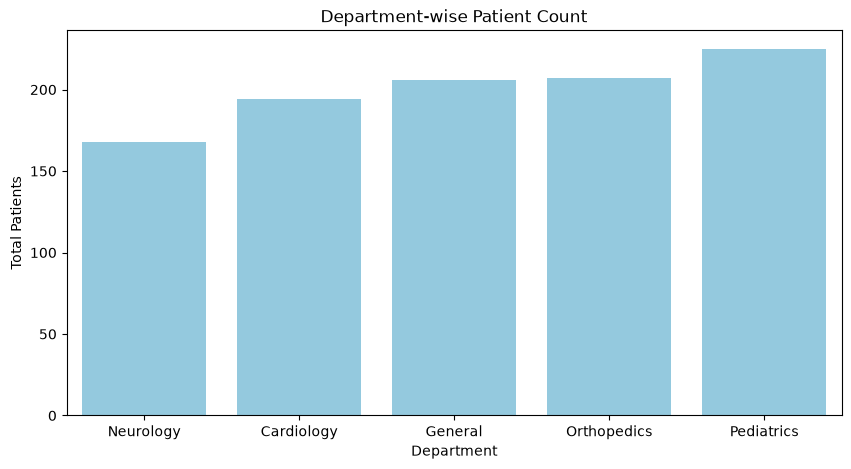

In [5]:
plt.figure(figsize=(10,5))
sns.countplot(data=df, x='Department',color='skyblue')
plt.title('Department-wise Patient Count')
plt.xlabel('Department')
plt.ylabel('Total Patients')
plt.savefig('visualizations/department_analysis.png',dpi=300,bbox_inches='tight')
plt.show()

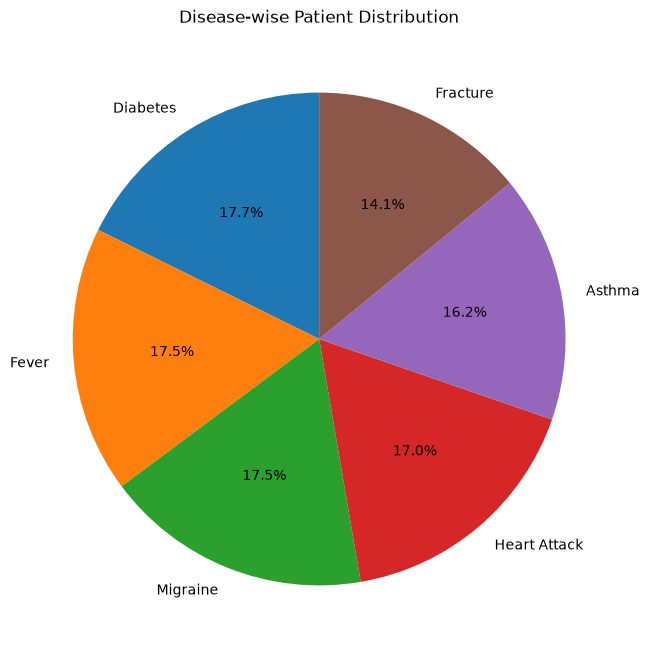

In [6]:
disease_count = df['Disease'].value_counts()
plt.figure(figsize=(8,8))
plt.pie(disease_count,labels=disease_count.index,autopct='%1.1f%%',startangle=90)
plt.title('Disease-wise Patient Distribution')
plt.savefig('visualizations/disease_distribution.png',dpi=300,bbox_inches='tight')
plt.show()

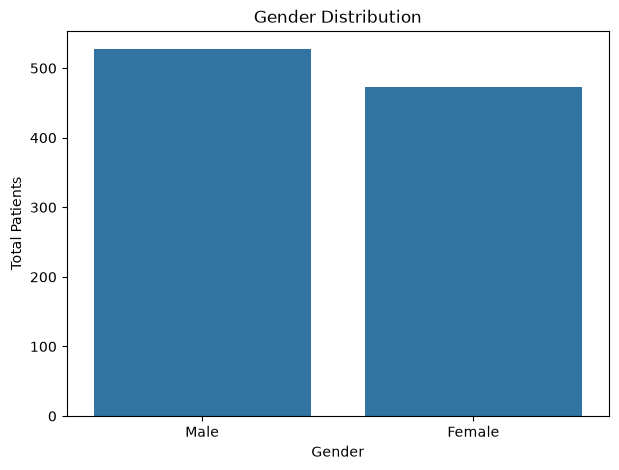

In [7]:
plt.figure(figsize=(7,5))
sns.countplot(data=df, x='Gender')
plt.title('Gender Distribution')
plt.xlabel('Gender')
plt.ylabel('Total Patients')
plt.savefig('visualizations/gender_distribution.png',dpi=300,bbox_inches='tight')
plt.show()

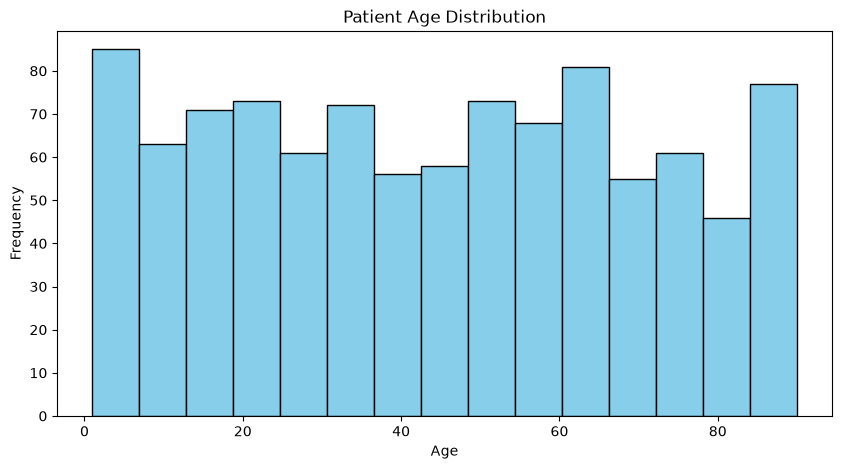

In [8]:
plt.figure(figsize=(10,5))
plt.hist(df['Age'], bins=15, color='skyblue', edgecolor='black')
plt.title('Patient Age Distribution')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.savefig('visualizations/age_distribution.png',dpi=300,bbox_inches='tight')
plt.show()

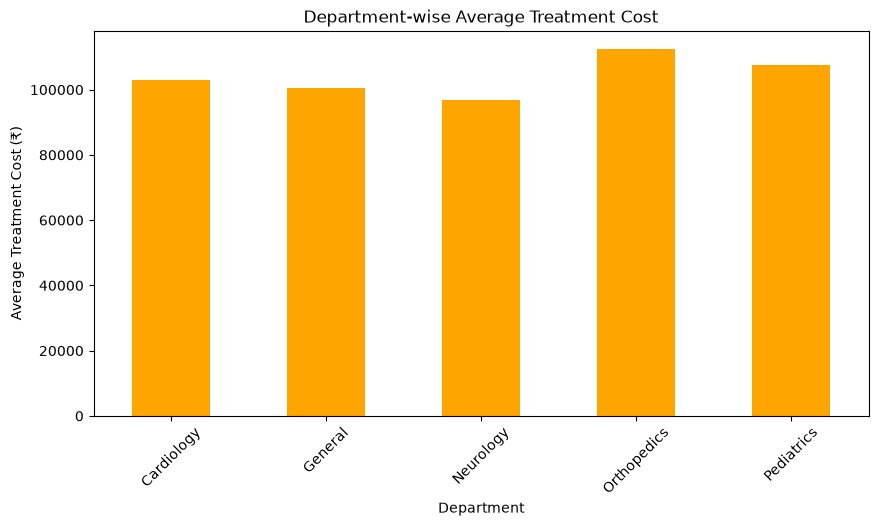

In [9]:
department_cost = df.groupby('Department')['Treatment_Cost'].mean()
plt.figure(figsize=(10,5))
department_cost.plot(kind='bar', color='orange')
plt.title('Department-wise Average Treatment Cost')
plt.xlabel('Department')
plt.ylabel('Average Treatment Cost (₹)')
plt.xticks(rotation=45)
plt.savefig('visualizations/department_treatment_cost.png',dpi=300,bbox_inches='tight')
plt.show()

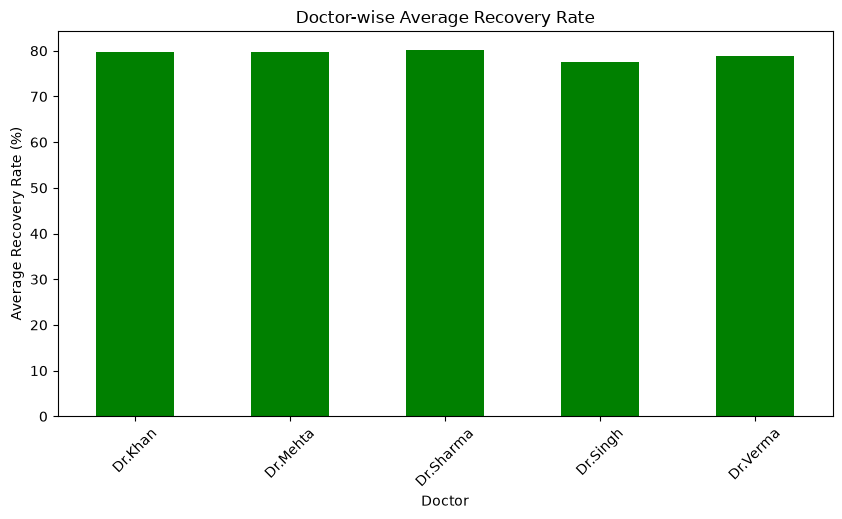

In [10]:
doctor_recovery = df.groupby('Doctor')['Recovery_Rate'].mean()
plt.figure(figsize=(10,5))
doctor_recovery.plot(kind='bar', color='green')
plt.title('Doctor-wise Average Recovery Rate')
plt.xlabel('Doctor')
plt.ylabel('Average Recovery Rate (%)')
plt.xticks(rotation=45)
plt.savefig('visualizations/doctor_recovery_rate.png',dpi=300,bbox_inches='tight')
plt.show()

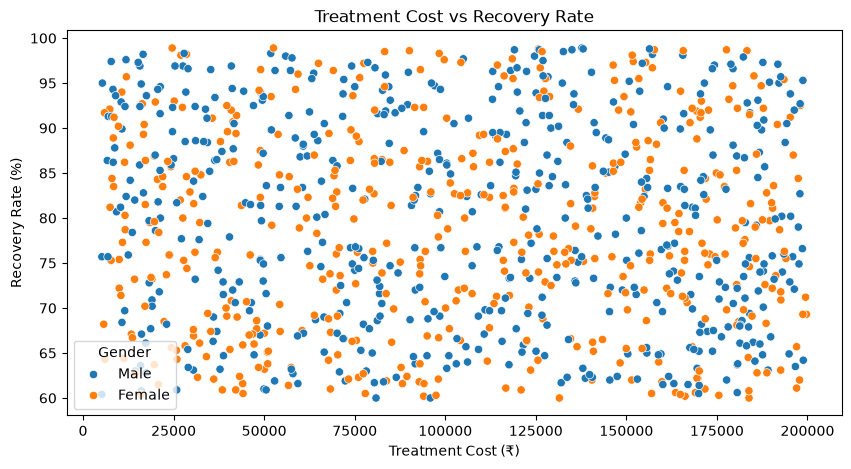

In [11]:
plt.figure(figsize=(10,5))
sns.scatterplot(data=df,x='Treatment_Cost',y='Recovery_Rate',hue='Gender')
plt.title('Treatment Cost vs Recovery Rate')
plt.xlabel('Treatment Cost (₹)')
plt.ylabel('Recovery Rate (%)')
plt.savefig('visualizations/cost_vs_recovery.png',dpi=300,bbox_inches='tight')
plt.show()

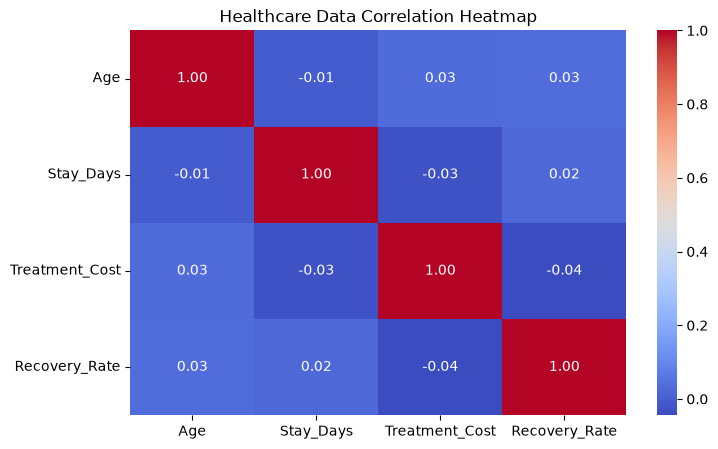

In [12]:
plt.figure(figsize=(8,5))
sns.heatmap(df[['Age', 'Stay_Days', 'Treatment_Cost','Recovery_Rate']].corr(),annot=True,cmap='coolwarm',fmt='.2f')
plt.title('Healthcare Data Correlation Heatmap')
plt.savefig('visualizations/healthcare_data_correlation',dpi=300,bbox_inches='tight')
plt.show()

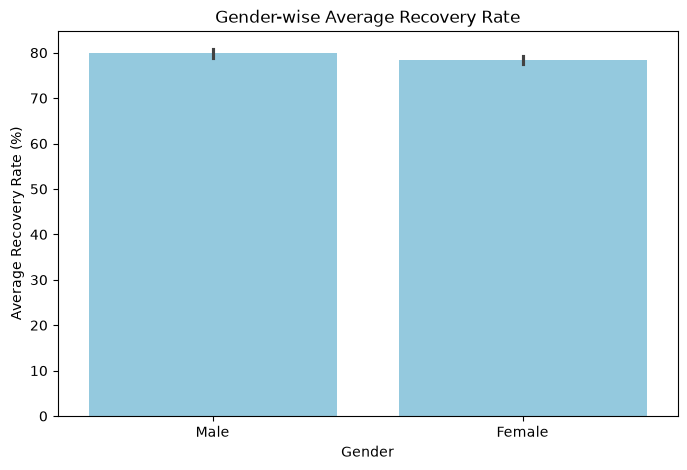

In [13]:
plt.figure(figsize=(8,5))
sns.barplot(data=df,x='Gender',y='Recovery_Rate',estimator='mean',color='skyblue')
plt.title('Gender-wise Average Recovery Rate')
plt.xlabel('Gender')
plt.ylabel('Average Recovery Rate (%)')
plt.savefig('visualizations/gender_recovery_rate',dpi=300,bbox_inches='tight')
plt.show()

In [ ]:
cleaned_df = hospital.data_cleaning(df)
stats_result = hospital.statistics(df)
print("Hospital Data Statistical Analysis:")
display(stats_result)
department_result = hospital.department_analysis(df)
print("Department-wise Hospital Analysis:")
display(department_result)
disease_result = hospital.disease_analysis(df)
print("Disease-wise Hospital Analysis:")
display(disease_result)
doctor_result = hospital.doctor_analysis(df)
print("Doctor-wise Hospital Analysis:")
display(doctor_result)
gender_result = hospital.gender_analysis(df)
print("Gender-wise Hospital Analysis:")
display(gender_result)


Missing Values:
Patient_ID        0
Age               0
Gender            0
Department        0
Disease           0
Admission_Date    0
Stay_Days         0
Treatment_Cost    0
Recovery_Rate     0
Doctor            0
Month             0
Age_Group         0
Cost_Category     0
dtype: int64
Duplicate Records:
0
Unique Patient IDs:
1000
Data Types:
Patient_ID                 int64
Age                        int32
Gender                       str
Department                   str
Disease                      str
Admission_Date    datetime64[us]
Stay_Days                  int32
Treatment_Cost             int32
Recovery_Rate            float64
Doctor                       str
Month                        str
Age_Group                    str
Cost_Category                str
dtype: object
Invalid Age:
Empty DataFrame
Columns: [Patient_ID, Age, Gender, Department, Disease, Admission_Date, Stay_Days, Treatment_Cost, Recovery_Rate, Doctor, Month, Age_Group, Cost_Category]
Index: []
Invalid Treatmen

,Mean,Median,Standard Deviation,25th Percentile Q1,50th Percentile Q2,75th Percentile Q3,Interquartile Range IQR
Age,44.27,45.00,26.36,21.00,45.00,65.00,44.00
Stay_Days,15.75,16.00,8.71,8.00,16.00,23.00,15.00
Treatment_Cost,104402.32,105626.00,57778.06,51979.75,105626.00,156469.25,104489.50
Recovery_Rate,79.16,79.05,11.23,69.40,79.05,88.62,19.22


Department-wise Hospital Analysis:


,Total_Patients,Average_Age,Average_Treatment_Cost,Average_Recovery_Rate,Total_Treatment_Cost
Department,,,,,
Cardiology,194,44.37,103024.12,79.05,19986679
General,206,42.77,100364.65,79.87,20675117
Neurology,168,45.48,96767.88,79.50,16257003
Orthopedics,207,46.85,112396.58,79.00,23266093
Pediatrics,225,42.29,107633.00,78.49,24217424


Disease-wise Hospital Analysis:


,Total_Patients,Average_Age,Average_Treatment_Cost,Maximum_Treatment_Cost,Average_Recovery_Rate,Total_Treatment_Cost
Disease,,,,,,
Diabetes,177,43.28,103643.65,197971,78.25,18344926
Fever,175,44.16,100145.10,199699,79.18,17525393
Migraine,175,42.80,108321.43,198594,79.01,18956251
Heart Attack,170,46.88,111336.25,199472,80.08,18927162
Asthma,162,43.28,105742.54,197656,79.28,17130291
Fracture,141,45.47,95874.42,198839,79.21,13518293


Doctor-wise Hospital Analysis:


,Total_Patients,Average_Age,Average_Treatment_Cost,Average_Recovery_Rate,Total_Treatment_Cost,Maximum_Recovery_Rate
Doctor,,,,,,
Dr.Sharma,182,43.49,98831.40,80.25,17987315,98.9
Dr.Khan,171,43.31,104727.78,79.76,17908451,98.8
Dr.Mehta,202,44.00,104024.53,79.68,21012956,98.7
Dr.Verma,232,46.01,107569.53,78.84,24956130,98.9
Dr.Singh,213,44.08,105809.69,77.60,22537464,98.9


Gender-wise Hospital Analysis:


,Total_Patients,Average_Age,Average_Treatment_Cost,Average_Recovery_Rate,Average_Stay_Days
Gender,,,,,
Female,473,45.84,103554.29,78.39,15.88
Male,527,42.86,105163.45,79.85,15.64


In [ ]:
!pip install openpyxl


   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpy

In [ ]:
with pd.ExcelWriter("Hospital_Analysis_Report.xlsx") as writer:
    df.to_excel(writer, sheet_name="Patient_Data", index=False)
    stats_result.to_excel(writer, sheet_name="Statistics")
    department_result.to_excel(writer, sheet_name="Department")
    disease_result.to_excel(writer, sheet_name="Disease")
    doctor_result.to_excel(writer, sheet_name="Doctor")
    gender_result.to_excel(writer, sheet_name="Gender")
print("All reports exported successfully!")

All reports exported successfully!
